# PCA Experiments

This notebook investigates whether Principal Component Analysis (PCA) improves classification of schizophrenia, bipolar disorder and healthy controls using gene-expression data.

PCA experiments will be compared with models using the original features. Imputation, scaling and PCA will be fitted within each cross-validation fold to avoid data leakage. The held-out test set will not be used to select the number of components.

## Imports

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import make_scorer, f1_score

RANDOM_STATE = 42

print("PCA notebook imports successful.")


PCA notebook imports successful.


## Paths & Loading Data

In [2]:

from pathlib import Path

PROJECT_DIR = Path.cwd().parent
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

X = pd.read_csv(
    PROCESSED_DIR / "expression_matrix.csv",
    index_col=0,
)
metadata = pd.read_csv(
    PROCESSED_DIR / "sample_metadata.csv",
    index_col=0,
)

print("Expression matrix:", X.shape)
print("Metadata:", metadata.shape)
print("Metadata columns:", metadata.columns.tolist())


Expression matrix: (88, 30635)
Metadata: (88, 8)
Metadata columns: ['title', 'tissue', 'disease state', 'age', 'population', 'dsm-iv', 'age of onset', 'gender']


## Exclude GSM1521674

In [3]:

EXCLUDED_SAMPLE = "GSM1521674"

# Exclude the sample flagged during data-quality review.
X = X.drop(index=EXCLUDED_SAMPLE, errors="ignore")

# Match metadata rows to the expression matrix.
if "sample_id" in metadata.columns:
    metadata = metadata.set_index("sample_id")

metadata = metadata.loc[X.index]

y = metadata["disease state"]

assert X.index.equals(y.index)
assert y.notna().all()
assert X.index.is_unique

print("Feature matrix:", X.shape)
print("\nClass distribution:")
print(y.value_counts())


Feature matrix: (87, 30635)

Class distribution:
disease state
bipolar disorder    29
healthy control     29
schizophrenia       29
Name: count, dtype: int64


## Split training and testing, stratification

In [4]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y,
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)

print("Training samples:", len(X_train))
print("Test samples:", len(X_test))
print("\nTraining class counts:")
print(y_train.value_counts())
print("\nTest class counts:")
print(y_test.value_counts())

Training samples: 69
Test samples: 18

Training class counts:
disease state
bipolar disorder    23
schizophrenia       23
healthy control     23
Name: count, dtype: int64

Test class counts:
disease state
schizophrenia       6
healthy control     6
bipolar disorder    6
Name: count, dtype: int64


## Comparing Logistic Regression With and Without PCA

PCA reduces the number of input features by transforming gene-expression measurements into principal components. This experiment compares logistic regression using the original features with logistic regression using reduced representations.

The number of components will be selected using cross-validation on the training set only. The test set will remain untouched during model selection.

In [5]:

from sklearn.model_selection import cross_val_score

# Use the same logistic regression settings as the earlier experiment.
# PCA is fitted separately inside each cross-validation fold.

component_options = [10, 25, 50]

pca_results = []

# First, evaluate logistic regression without PCA.
baseline_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        C=1.0,
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    )),
])

baseline_scores = cross_val_score(
    baseline_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1,
)

pca_results.append({
    "Components": "No PCA",
    "Mean CV macro F1": baseline_scores.mean(),
    "Std CV macro F1": baseline_scores.std(),
})

# Now evaluate PCA with different component counts.
for n_components in component_options:
    pca_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("pca", PCA(
            n_components=n_components,
            random_state=RANDOM_STATE,
        )),
        ("classifier", LogisticRegression(
            C=1.0,
            max_iter=2000,
            class_weight="balanced",
            random_state=RANDOM_STATE,
        )),
    ])

    scores = cross_val_score(
        pca_pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="f1_macro",
        n_jobs=-1,
    )

    pca_results.append({
        "Components": n_components,
        "Mean CV macro F1": scores.mean(),
        "Std CV macro F1": scores.std(),
    })

pca_results_df = pd.DataFrame(pca_results).sort_values(
    "Mean CV macro F1",
    ascending=False,
).reset_index(drop=True)

display(pca_results_df.round(3))


,Components,Mean CV macro F1,Std CV macro F1
0,50,0.419,0.047
1,No PCA,0.398,0.077
2,25,0.342,0.081
3,10,0.319,0.075


## Test a wider range of PCA component numbers

In [7]:
component_options = [5, 10, 15, 20, 25, 30, 35, 40, 45, 50]

pca_results = []

for n_components in component_options:

    pca_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=n_components)),
        ("classifier", LogisticRegression(
            C=1.0,
            class_weight="balanced",
            max_iter=2000,
            random_state=42
        ))
    ])

    scores = cross_val_score(
        pca_pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="f1_macro",
        n_jobs=-1
    )

    pca_results.append({
        "Components": n_components,
        "Mean CV macro F1": scores.mean(),
        "Std CV macro F1": scores.std()
    })

pca_results_df = pd.DataFrame(pca_results)

pca_results_df = pca_results_df.sort_values(
    by="Mean CV macro F1",
    ascending=False
).reset_index(drop=True)

display(pca_results_df.round(3))

,Components,Mean CV macro F1,Std CV macro F1
0,50,0.419,0.047
1,15,0.408,0.046
2,40,0.374,0.083
3,30,0.368,0.138
4,25,0.364,0.117
5,45,0.349,0.060
6,20,0.329,0.129
7,10,0.328,0.070
8,35,0.320,0.095
9,5,0.225,0.131


## PCA Logistic Regression

PCA Logistic Regression — Test Results
PCA components: 50
Accuracy: 0.444
Macro F1: 0.426

Classification report:
                  precision    recall  f1-score   support

bipolar disorder       0.60      0.50      0.55         6
 healthy control       0.44      0.67      0.53         6
   schizophrenia       0.25      0.17      0.20         6

        accuracy                           0.44        18
       macro avg       0.43      0.44      0.43        18
    weighted avg       0.43      0.44      0.43        18



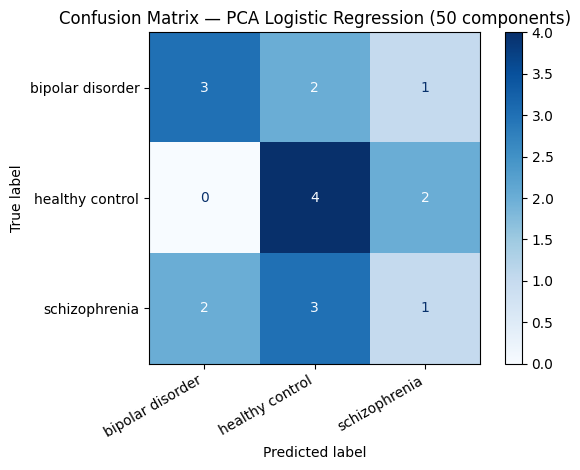

In [8]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Build the PCA + tuned logistic regression pipeline
best_pca_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=50)),
    ("classifier", LogisticRegression(
        C=1.0,
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

# Fit using training data only
best_pca_model.fit(X_train, y_train)

# Evaluate on the held-out test set
y_pred_pca = best_pca_model.predict(X_test)

print("PCA Logistic Regression — Test Results")
print("PCA components:", 50)
print("Accuracy:", round(accuracy_score(y_test, y_pred_pca), 3))
print(
    "Macro F1:",
    round(f1_score(y_test, y_pred_pca, average="macro"), 3)
)

print("\nClassification report:")
print(classification_report(y_test, y_pred_pca, zero_division=0))

# Confusion matrix
labels = ["bipolar disorder", "healthy control", "schizophrenia"]

cm = confusion_matrix(y_test, y_pred_pca, labels=labels)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix — PCA Logistic Regression (50 components)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## KNN and Random Forest PCA


KNN + PCA (50)
Accuracy: 0.389
Macro F1: 0.371

Classification report:
                  precision    recall  f1-score   support

bipolar disorder       1.00      0.17      0.29         6
 healthy control       0.33      0.50      0.40         6
   schizophrenia       0.38      0.50      0.43         6

        accuracy                           0.39        18
       macro avg       0.57      0.39      0.37        18
    weighted avg       0.57      0.39      0.37        18



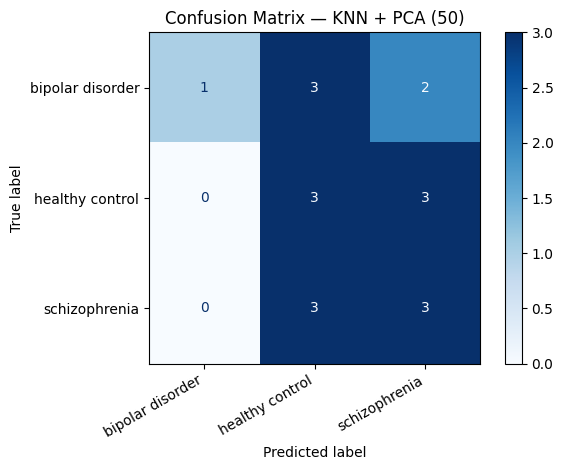


Random Forest + PCA (50)
Accuracy: 0.333
Macro F1: 0.326

Classification report:
                  precision    recall  f1-score   support

bipolar disorder       0.20      0.17      0.18         6
 healthy control       0.43      0.50      0.46         6
   schizophrenia       0.33      0.33      0.33         6

        accuracy                           0.33        18
       macro avg       0.32      0.33      0.33        18
    weighted avg       0.32      0.33      0.33        18



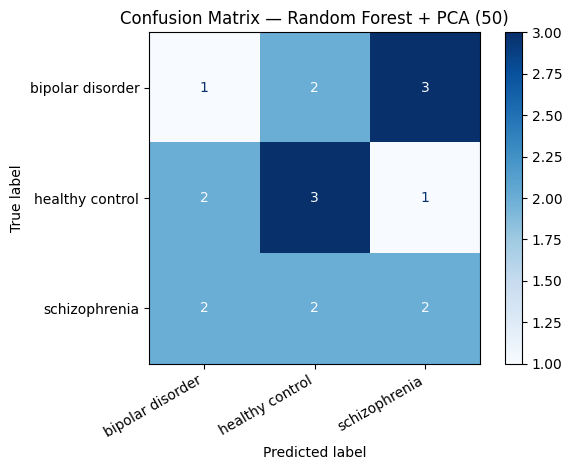


PCA model test comparison:


,Model,Accuracy,Macro F1
0,KNN + PCA (50),0.389,0.371
1,Random Forest + PCA (50),0.333,0.326


In [9]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

# Define the two PCA models using the best settings found so far.
pca_models = {
    "KNN + PCA (50)": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=50)),
        ("classifier", KNeighborsClassifier(
            n_neighbors=9,
            weights="distance"
        ))
    ]),

    "Random Forest + PCA (50)": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=50)),
        ("classifier", RandomForestClassifier(
            n_estimators=100,
            min_samples_leaf=1,
            max_depth=None,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ])
}

pca_test_results = []

labels = [
    "bipolar disorder",
    "healthy control",
    "schizophrenia"
]

# Fit and evaluate each model on the same held-out test set.
for model_name, model in pca_models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    macro_f1 = f1_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    pca_test_results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Macro F1": macro_f1
    })

    print(f"\n{'=' * 55}")
    print(model_name)
    print("Accuracy:", round(accuracy, 3))
    print("Macro F1:", round(macro_f1, 3))

    print("\nClassification report:")
    print(classification_report(
        y_test,
        y_pred,
        labels=labels,
        zero_division=0
    ))

    cm = confusion_matrix(y_test, y_pred, labels=labels)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=labels
    )
    disp.plot(cmap="Blues", values_format="d")
    plt.title(f"Confusion Matrix — {model_name}")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

pca_test_results_df = pd.DataFrame(pca_test_results)

print("\nPCA model test comparison:")
display(pca_test_results_df.round(3))

## Comparing PCAs for each model individually

In [12]:
from sklearn.base import clone

RANDOM_STATE = 42

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

models = {
    "Logistic regression": LogisticRegression(
        C=1.0,
        class_weight="balanced",
        max_iter=2000,
        random_state=RANDOM_STATE
    ),
    "KNN": KNeighborsClassifier(
        n_neighbors=9,
        weights="distance"
    ),
    "Random forest": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=1
    )
}

component_options = [5, 10, 15, 20, 25, 30, 35, 40, 45, 50]

pca_results = []

for model_name, classifier in models.items():
    for n_components in component_options:

        pipeline = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("pca", PCA(n_components=n_components)),
            ("classifier", clone(classifier))
        ])

        scores = cross_val_score(
            pipeline,
            X_train,
            y_train,
            cv=cv,
            scoring="f1_macro",
            n_jobs=-1,
            error_score="raise"
        )

        pca_results.append({
            "Model": model_name,
            "Components": n_components,
            "Mean CV macro F1": scores.mean(),
            "Std CV macro F1": scores.std()
        })

pca_results_df = pd.DataFrame(pca_results)

display(
    pca_results_df
    .sort_values("Mean CV macro F1", ascending=False)
    .round(3)
    .reset_index(drop=True)
)


,Model,Components,Mean CV macro F1,Std CV macro F1
0,Logistic regression,50,0.419,0.047
1,Random forest,45,0.413,0.096
2,Logistic regression,15,0.406,0.076
3,Logistic regression,40,0.382,0.062
4,Logistic regression,20,0.364,0.107
5,Random forest,40,0.357,0.025
6,Random forest,25,0.352,0.100
7,Logistic regression,45,0.349,0.060
8,Logistic regression,30,0.345,0.087
9,Random forest,50,0.343,0.071


In [13]:

best_pca_results = (
    pca_results_df
    .sort_values("Mean CV macro F1", ascending=False)
    .groupby("Model")
    .first()
    .reset_index()
    .sort_values("Mean CV macro F1", ascending=False)
)

display(best_pca_results.round(3))


,Model,Components,Mean CV macro F1,Std CV macro F1
1,Logistic regression,50,0.419,0.047
2,Random forest,45,0.413,0.096
0,KNN,50,0.340,0.107


In [14]:
comparison_results = []

# First: evaluate each model WITHOUT PCA
for model_name, classifier in models.items():

    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", clone(classifier))
    ])

    scores = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="f1_macro",
        n_jobs=-1
    )

    comparison_results.append({
        "Model": model_name,
        "Method": "No PCA",
        "Components": "N/A",
        "Mean CV macro F1": scores.mean(),
        "Std CV macro F1": scores.std()
    })

# Then: add the best PCA result for each model
for _, row in best_pca_results.iterrows():

    comparison_results.append({
        "Model": row["Model"],
        "Method": "PCA",
        "Components": int(row["Components"]),
        "Mean CV macro F1": row["Mean CV macro F1"],
        "Std CV macro F1": row["Std CV macro F1"]
    })

comparison_df = pd.DataFrame(comparison_results)

display(
    comparison_df
    .sort_values("Mean CV macro F1", ascending=False)
    .round(3)
    .reset_index(drop=True)
)

,Model,Method,Components,Mean CV macro F1,Std CV macro F1
0,Logistic regression,PCA,50,0.419,0.047
1,Random forest,PCA,45,0.413,0.096
2,Logistic regression,No PCA,N/A,0.398,0.077
3,KNN,PCA,50,0.340,0.107
4,KNN,No PCA,N/A,0.338,0.117
5,Random forest,No PCA,N/A,0.332,0.061


## Final Comparisons

In [15]:

best_components = {
    "Logistic regression": 50,
    "Random forest": 45,
    "KNN": 50
}

final_test_results = []
final_pca_models = {}

for model_name, n_components in best_components.items():

    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=n_components)),
        ("classifier", clone(models[model_name]))
    ])

    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)

    final_pca_models[model_name] = pipeline

    final_test_results.append({
        "Model": model_name,
        "PCA components": n_components,
        "Test accuracy": accuracy_score(y_test, y_pred),
        "Test macro F1": f1_score(
            y_test, y_pred, average="macro"
        )
    })

    print(f"\n{model_name} + PCA ({n_components} components)")
    print(classification_report(y_test, y_pred, zero_division=0))

final_test_results_df = pd.DataFrame(final_test_results)

display(
    final_test_results_df
    .sort_values("Test macro F1", ascending=False)
    .round(3)
    .reset_index(drop=True)
)


Logistic regression + PCA (50 components)
                  precision    recall  f1-score   support

bipolar disorder       0.60      0.50      0.55         6
 healthy control       0.44      0.67      0.53         6
   schizophrenia       0.25      0.17      0.20         6

        accuracy                           0.44        18
       macro avg       0.43      0.44      0.43        18
    weighted avg       0.43      0.44      0.43        18


Random forest + PCA (45 components)
                  precision    recall  f1-score   support

bipolar disorder       0.00      0.00      0.00         6
 healthy control       0.50      0.67      0.57         6
   schizophrenia       0.38      0.50      0.43         6

        accuracy                           0.39        18
       macro avg       0.29      0.39      0.33        18
    weighted avg       0.29      0.39      0.33        18


KNN + PCA (50 components)
                  precision    recall  f1-score   support

bipolar disorder

,Model,PCA components,Test accuracy,Test macro F1
0,Logistic regression,50,0.444,0.426
1,KNN,50,0.389,0.371
2,Random forest,45,0.389,0.333


In [16]:
# Compare the cross-validation results with the held-out test results.
# Uses your existing variables; no imports needed.

final_comparison = pd.DataFrame([
    {
        "Model": "Logistic regression",
        "Method": "PCA",
        "Components": 50,
        "CV macro F1": 0.419,
        "CV F1 std": 0.047,
        "Test accuracy": 0.444,
        "Test macro F1": 0.426
    },
    {
        "Model": "Random forest",
        "Method": "PCA",
        "Components": 45,
        "CV macro F1": 0.413,
        "CV F1 std": 0.096,
        "Test accuracy": 0.389,
        "Test macro F1": 0.333
    },
    {
        "Model": "KNN",
        "Method": "PCA",
        "Components": 50,
        "CV macro F1": 0.340,
        "CV F1 std": 0.107,
        "Test accuracy": 0.389,
        "Test macro F1": 0.371
    }
])

display(
    final_comparison
    .sort_values("CV macro F1", ascending=False)
    .round(3)
)

,Model,Method,Components,CV macro F1,CV F1 std,Test accuracy,Test macro F1
0,Logistic regression,PCA,50,0.419,0.047,0.444,0.426
1,Random forest,PCA,45,0.413,0.096,0.389,0.333
2,KNN,PCA,50,0.340,0.107,0.389,0.371


In [17]:
# Add the existing DummyClassifier results from Notebook 2

final_comparison.loc[len(final_comparison)] = {
    "Model": "DummyClassifier",
    "Method": "Baseline",
    "Components": "N/A",
    "CV macro F1": 0.150,
    "CV F1 std": 0.003,
    "Test accuracy": 0.333,
    "Test macro F1": 0.167
}

display(
    final_comparison
    .sort_values("Test macro F1", ascending=False)
    .round(3)
    .reset_index(drop=True)
)

,Model,Method,Components,CV macro F1,CV F1 std,Test accuracy,Test macro F1
0,Logistic regression,PCA,50,0.419,0.047,0.444,0.426
1,KNN,PCA,50,0.340,0.107,0.389,0.371
2,Random forest,PCA,45,0.413,0.096,0.389,0.333
3,DummyClassifier,Baseline,N/A,0.150,0.003,0.333,0.167


## Results and Interpretation

Logistic regression with 50 PCA components achieved the highest held-out test macro-F1 score (0.426) and test accuracy (0.444) among the evaluated models. K-nearest neighbours achieved a test macro-F1 of 0.371, while random forest achieved 0.333. All three PCA-based models obtained higher test macro-F1 scores than the DummyClassifier baseline (0.167).

The cross-validation results also favoured logistic regression, with a mean macro-F1 of 0.419 and a standard deviation of 0.047. Random forest had a similar mean cross-validation macro-F1 of 0.413, but a higher standard deviation of 0.096, indicating greater variation across the validation folds.

These findings suggest that logistic regression is the most promising of the tested configurations. However, the held-out test set contains only 18 samples, with six from each class, so the metrics are sensitive to individual predictions.